# Risk Recon: Historical ETF Risk Baseline

The folllowing presents daily returns, historical volatility, and correlations for GLD, IWM, QQQ, SPY, and TLT. These estimates will provide a baseline for the portfolio simulation engine.

The extraction script already computes simple returns from adjusted closing prices:

$$
r_t = \frac{P_t}{P_{t-1}} - 1 = \frac{P_t - P_{t-1}}{P_{t-1}}
$$

The CSV contains fractional returns: `0.01` means `1%`.


In [27]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TRADING_DAYS = 252
TICKERS = ['GLD', 'IWM', 'QQQ', 'SPY', 'TLT']


## 1. Data Load and Validation

Resolve CSV and verify values.


In [28]:
csv_path = next((p for p in [Path('./etf_returns.csv'), Path('../etf_returns.csv')] if p.is_file()), None)

if csv_path is None:
    raise FileNotFoundError('Run this notebook from the project root or analysis directory.')

dataset = pd.read_csv(csv_path, parse_dates=['Date']).set_index('Date').sort_index()

if dataset.index.hasnans or dataset.index.has_duplicates:
    raise ValueError('Dates must be valid and unique.')
if set(dataset.columns) != set(TICKERS):
    raise ValueError(f'Expected ETF columns: {TICKERS}')

returns = dataset[TICKERS].apply(pd.to_numeric, errors='raise')

if returns.empty or len(returns) < 2 or not np.isfinite(returns.to_numpy()).all():
    raise ValueError('Need at least two observations and no missing or infinite returns.')
if (returns < -1).any().any():
    raise ValueError('Simple returns cannot be below -100%.')

print(f'{len(returns):,} observations: {returns.index.min().date()} to {returns.index.max().date()}')
display(returns.isna().sum().rename('Missing observations').to_frame())


4,232 observations: 2010-01-05 to 2026-10-30


,Missing observations
GLD,0
IWM,0
QQQ,0
SPY,0
TLT,0


## 2. Daily Percentage Returns

The plot showcases daily moves in percentage points.


,GLD,IWM,QQQ,SPY,TLT
Date,,,,,
2010-01-05,-0.09%,-0.34%,0.00%,0.26%,0.65%
2010-01-06,1.65%,-0.09%,-0.60%,0.07%,-1.34%
2010-01-07,-0.62%,0.74%,0.07%,0.42%,0.17%
2010-01-08,0.50%,0.55%,0.82%,0.33%,-0.04%
2010-01-11,1.33%,-0.40%,-0.41%,0.14%,-0.55%
2010-01-12,-2.09%,-1.09%,-1.25%,-0.93%,1.71%
2010-01-13,0.95%,1.29%,1.25%,0.84%,-1.16%
2010-01-14,0.44%,0.37%,0.09%,0.27%,1.40%
2010-01-15,-1.04%,-1.45%,-1.16%,-1.12%,0.62%


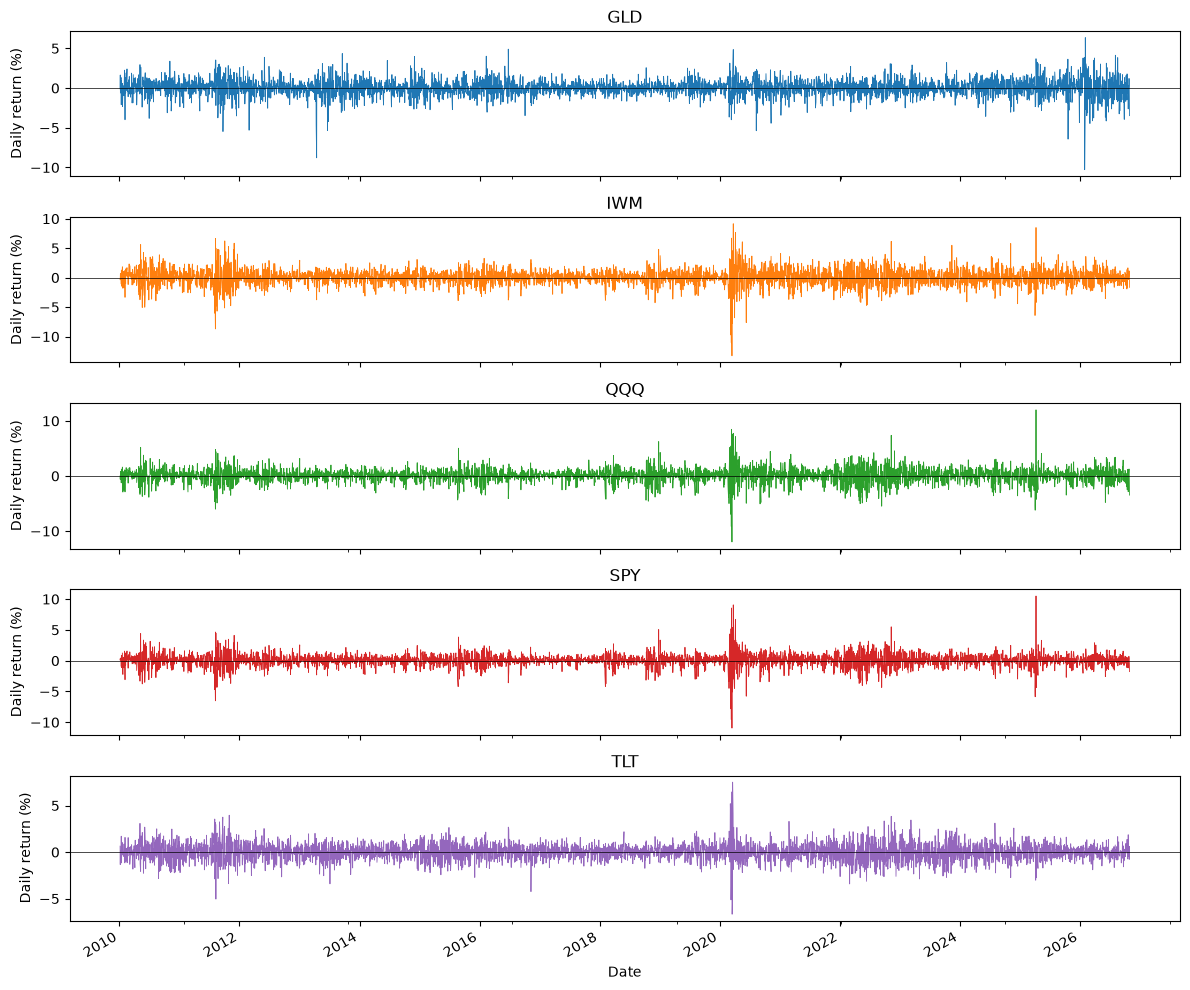

In [29]:
display(returns.head(10).apply(lambda column: column.map('{:.2%}'.format)))

ax = returns.mul(100).plot(subplots=True, figsize=(12, 10), sharex=True, legend=False, linewidth=0.6)

for axis, ticker in zip(ax, returns.columns):
    axis.set_title(ticker)
    axis.set_ylabel('Daily return (%)')
    axis.axhline(0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

## 3. Extrema and Range

The following presents the extrema in the daily returns for each ticker. The range in percentage points on the extrema for each ticker is also provided.

In [30]:
daily_extremes = pd.DataFrame({
    'Max daily return': returns.max(),
    'Max date': returns.idxmax(),
    'Min daily return': returns.min(),
    'Min date': returns.idxmin(),
})

display(daily_extremes.apply(lambda column:
                             column.map('{:.2%}'.format)
                             if 'return' in column.name
                             else column.dt.strftime('%Y-%m-%d')
))

daily_return_range = pd.DataFrame({
    'Daily return range': returns.max() - returns.min()
})

display(daily_return_range.mul(100).apply(lambda column:
                                 column.map('{:.2f} pp'.format)
                                 ))

,Max daily return,Max date,Min daily return,Min date
GLD,6.36%,2026-02-03,-10.27%,2026-01-30
IWM,9.15%,2020-03-24,-13.27%,2020-03-16
QQQ,12.00%,2025-04-09,-11.98%,2020-03-16
SPY,10.50%,2025-04-09,-10.94%,2020-03-16
TLT,7.52%,2020-03-20,-6.67%,2020-03-17


,Daily return range
GLD,16.63 pp
IWM,22.42 pp
QQQ,23.98 pp
SPY,21.44 pp
TLT,14.19 pp


Note that **QQQ** has the greatest maximum daily return (12.00%), while also having the largest daily return range (24 pp). It's also the most balanced around zero. **IWM** follows with the second largest daily return range (22 pp), but a smaller, and smallest, minimum daily return (-13.27%).


## 3. Historical Volatility

Daily volatility is the sample standard deviation of daily returns:

$$
s_{\text{daily}} = \sqrt{\frac{1}{N-1} \sum_{t=1}^{N}(r_t - \bar{r})^2}
$$


Annualized volatility:

$$
s_{\text{annual}} = s_{\text{daily}} \sqrt{252}
$$

This assumes 252 trading days per year, stable daily variance, and uncorrelated returns across days. Variance adds over time under these assumptions, so standard deviation scales with the square root of time. For example, daily volatility of $1\%$ corresponds to annualized volatility of approximately $15.9\%$.

This is merely a historical estimate; mean daily return is also included for context.


,Mean daily return,Daily volatility,Annualized volatility
GLD,0.03%,1.06%,16.81%
IWM,0.05%,1.39%,22.10%
QQQ,0.08%,1.30%,20.65%
SPY,0.06%,1.07%,17.02%
TLT,0.01%,0.94%,14.88%


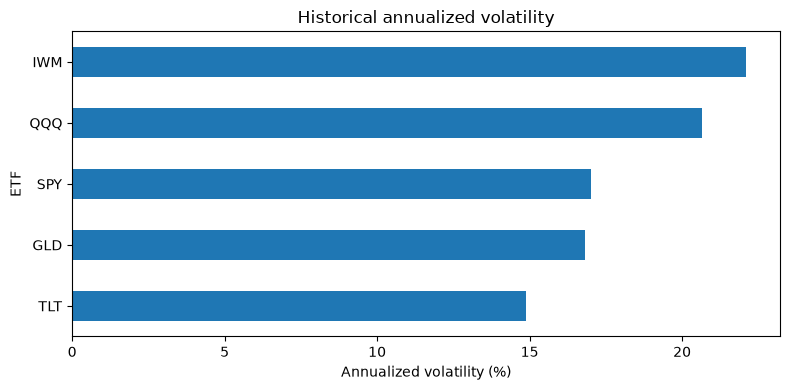

In [31]:
daily_volatility = returns.std(ddof=1)

annualized_volatility = daily_volatility * np.sqrt(TRADING_DAYS)

summary = pd.DataFrame({
    'Mean daily return': returns.mean(),
    'Daily volatility': daily_volatility,
    'Annualized volatility': annualized_volatility,
})

display(summary.apply(lambda column: column.map('{:.2%}'.format)))

annualized_volatility.mul(100).sort_values().plot.barh(
    figsize=(8, 4), title='Historical annualized volatility',
    xlabel='Annualized volatility (%)', ylabel='ETF',
)

plt.tight_layout()
plt.show()


Note that all ETFs yield a positive mean daily return, reinforcing the idea that, generally, investors are rewarded with positive returns over time.

Additionally, over the sample period, ETFs with higher daily volatility tended to have higher mean daily returns. See the scatter plot below.

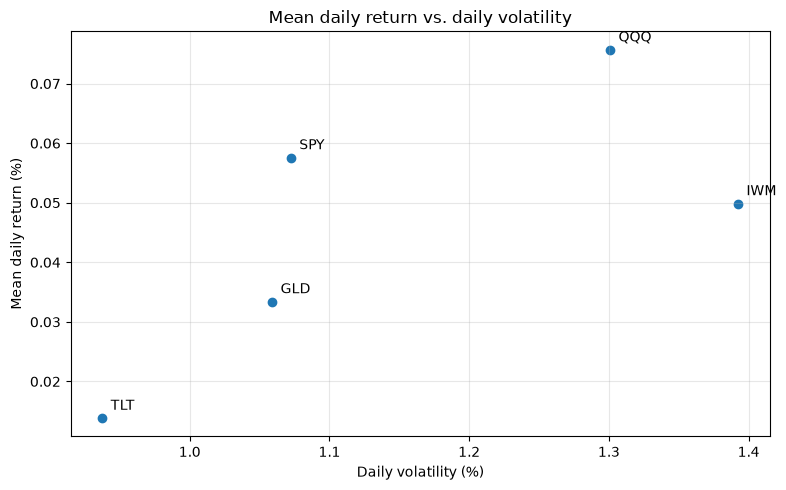

In [32]:
x = summary['Daily volatility'] * 100
y = summary['Mean daily return'] * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y)

for ticker in summary.index:
    ax.annotate(
        ticker,
        (x[ticker], y[ticker]),
        xytext=(6, 6),
        textcoords='offset points',
    )

ax.set_xlabel('Daily volatility (%)')
ax.set_ylabel('Mean daily return (%)')
ax.set_title('Mean daily return vs. daily volatility')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Correlation of Daily Returns

Pearson correlation measures linear co-movement, from -1 to +1. Near +1 means similar daily moves; near -1 means opposite moves; near zero means weak linear association. Correlation does not capture all dependence and can change during market stress.


,GLD,IWM,QQQ,SPY,TLT
GLD,1.000,0.084,0.082,0.074,0.206
IWM,0.084,1.000,0.792,0.881,-0.254
QQQ,0.082,0.792,1.000,0.930,-0.217
SPY,0.074,0.881,0.930,1.000,-0.283
TLT,0.206,-0.254,-0.217,-0.283,1.000


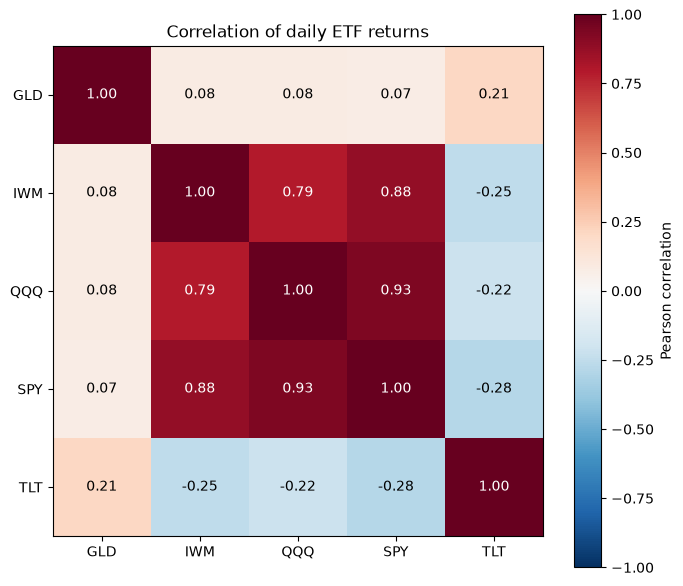

In [33]:
correlation = returns.corr(method='pearson')
display(correlation.round(3))

fig, ax = plt.subplots(figsize=(7, 6))
heatmap = ax.imshow(correlation.to_numpy(), vmin=-1, vmax=1, cmap='RdBu_r')

ax.set_xticks(range(len(TICKERS)), labels=TICKERS)
ax.set_yticks(range(len(TICKERS)), labels=TICKERS)

for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        value = correlation.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                color='white' if abs(value) > 0.6 else 'black')
        
fig.colorbar(heatmap, ax=ax, label='Pearson correlation')
ax.set_title('Correlation of daily ETF returns')

plt.tight_layout()
plt.show()


From the above heatmap, **QQQ** and **SPY** are the most coorelated in the positive direction, followed by **IWM** and **SPY**, then **IWM** and **QQQ**. This is consistent with their shared exposure to the US equity market. Overlapping holdings may further explain the strong coorelation between **QQQ** and **SPY**.

**TLT** shows weak negative correlations with the stock ETFs, suggesting some diversification potential over the same period: as stock values drop, investors may tend to move their investments into bonds and treasuries. 